# <h1 align ="center">**Plotting function** <h1>
Show aesthetics and options of the main plotting functions from the package. For selecting different palettes, refer to the official [matplotlib colormap](https://matplotlib.org/stable/gallery/color/colormap_reference.html) Below you can find:
1) [Graph plot function](#graph-plotting-function)
2) [Fused Gromov-Wasserstein coupling function](#fgw-coupling-function)
3) [Optimal transport batch coupling function](#optimal-transport-batch-coupling-function)

In [11]:
# Importation

# Suppress the known TorchScript deprecation emitted by imported dependencies.
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"^`torch\.jit\.script` is deprecated\. Please switch to `torch\.compile` or `torch\.export`\.$",
    category=FutureWarning,
    module=r"^torch\.jit\._script$",
)

#Mathematics and ML
import torch
import torch.nn.functional as F

#Project package
from graphtools import graphon, builder, metrics, opt

#Autoreload module
"""
These magic lines allow to automatically reload any module.py file when there are some changes on it, without the needing of restart the kernel anytime a new change is applied to the module script
"""
%load_ext autoreload
%autoreload 2

# Creation functions need an explicit target device. Metrics will infer it from the graph.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## <h1 align="center"> **Graph plotting function** <h1>
Display the graph adjacency matrix and graph nodes with generated spatial positions and optional Voronoi cells. Node coloring follows eventual label assignment.

In [12]:
# Sample a random graph with given assignments
n = 100
pos = "ring"
hist = "degree" #Type of graph histogram
state = "soft"
if state == "continuous":
    state_kwargs = {"d" : 3}
if state == "soft" or state == "hard":
    state_kwargs = {"K" : 5}
method_kwargs = {
    "epsilon": 0.3,
    "tolerance": 1e-9,
    "resolution": 32,
}
params = {
    "method" : "epsilon_voronoi",
    "add_voronoi" : True,
    "method_kwargs" : method_kwargs,
}

coordinates = graphon.sample_positions(n, pos, device=device)
graph = builder.build_graph(coordinates, **params)
graph.x = graphon.sample_states(n = n, device = device, state_type = state, **state_kwargs)
if state == "soft" or state == "hard":
    graph.labels = graph.x
if hist == "degree":
    tot_degree = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum()
    degrees = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum(dim = 0)
    graph.h = degrees / tot_degree

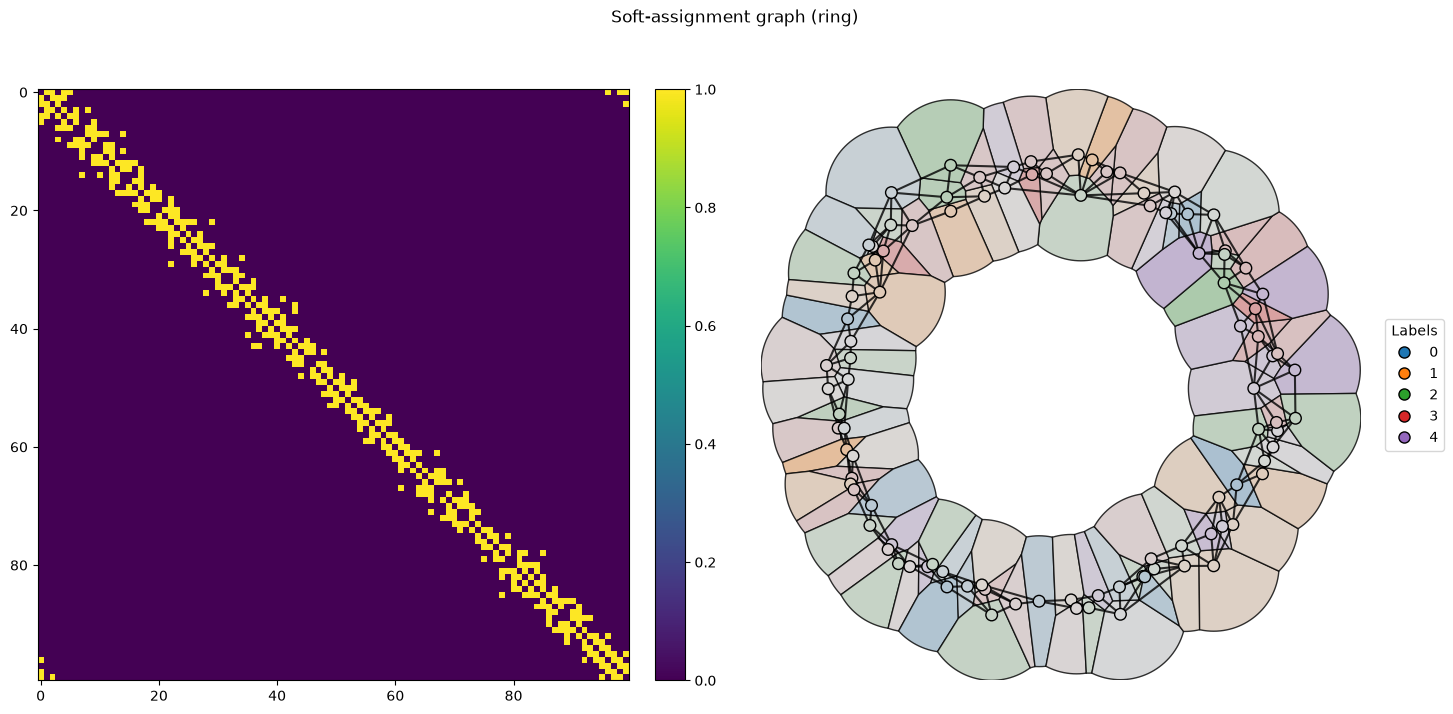

In [13]:
# Plot the graph
graphon.plot_graph(graph, title = f"Soft-assignment graph ({pos})", voronoi = True, show_legend = True)

In [14]:
# Plot one label distribution at a time
if state == "soft" or state == "hard":
    graphon.plot_graph(graph, title = f"Soft-assignment graph ({pos})", voronoi = True, mode = "heatmap", show_legend = True)

## <h1 align="center"> **FGW coupling function** <h1>
Plot the result of fused Gromov-Wasserstein coupling between nodes of two different graphs.

In [15]:
# Plot node alignments between a couple of annotated graphs
# Hyperparameters
positions = ["ring", "bubbles"] # Nodes positions
n = [100, 100] # Graph sizes
states = ["soft", "hard"] # Node states
hist = "degree" #Type of graph histogram
K = 3 # SBM communities

state_kwargs = {}
for i, state in enumerate(states):
    if state == "continuous":
        state_kwargs[str(i)] = {"d" : 5}
    elif state == "soft" or state == "hard":
        state_kwargs[str(i)] = {"K" : 5}
method_kwargs = {
    "epsilon": 0.3,
    "tolerance": 1e-9,
    "resolution": 32,
}
params = {
    "method" : "epsilon_voronoi",
    "add_voronoi" : True,
    "method_kwargs" : method_kwargs,
}

graphs = []
for pos, size, state, state_kwarg in zip(positions, n, states, state_kwargs.values()):
    if pos == "bubbles":
        coordinates = graphon.sample_positions(n = size, device = device, position_type = pos, K = K, radius_polygon = 0.5)
    else:
        coordinates = graphon.sample_positions(n = size, device = device, position_type = pos)
    graph = builder.build_graph(coordinates, **params)
    if hist == "degree":
        tot_degree = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum()
        degrees = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum(dim = 0)
        graph.h = degrees / tot_degree
    
    # Add node features
    graph.x = graphon.sample_states(n = size, device = device, state_type = state, **state_kwarg)
    if state == "soft" or state == "hard":
        graph.labels = graph.x
    graphs.append(graph)

In [16]:
# Compute FGW plan
loss, info = opt.fused_gromov_wasserstein_distance(graphs[0], graphs[1], feature_type = "soft")
# Plot FGW coupling
opt.plot_coupling_fgw(graphs[0], graphs[1], info["T"], show_marginals = True, title = "FGW coupling", voronoi = True, mode = "heatmap")

## <h1 align="center"> **Optimal transport batch coupling function** <h1>
Plot results of optimal transport batch coupling performed between two batches of graphs using Hungarian matching.

In [17]:
# Sample empirical batches
B = 20 # Batch size
sizes = [100, 200] # Graph sizes for the two batches

# Hyperparameters
positions = ["ring", "bubbles", "circle"]
state = "soft"
hist = "degree" #Type of graph histogram
K = 3 # SBM communities
if state == "continuous":
    state_kwargs = {"d" : 3}
if state == "soft" or state == "hard":
    state_kwargs = {"K" : 3}
method_kwargs = {
    "epsilon": 0.3,
    "tolerance": 1e-9,
    "resolution": 32,
}
params = {
    "method" : "epsilon_voronoi",
    "add_voronoi" : True,
    "method_kwargs" : method_kwargs,
}

batches = {
    "0" : [],
    "1" : [],
}
for pos in positions:
    for _ in range(B // len(positions)):
        # First batch graphs
        if pos == "bubbles":
            coordinates = graphon.sample_positions(n = sizes[0], device = device, position_type = pos, K = K, radius_polygon = 0.5)
        else:
            coordinates = graphon.sample_positions(n = sizes[0], device = device, position_type = pos)
        graph_1 = builder.build_graph(coordinates, **params)
        graph_1.C = metrics.adjacency_matrix(graph_1, normalized = False, sparse = False)

        # Second batch graphs
        if pos == "bubbles":
            coordinates = graphon.sample_positions(n = sizes[1], device = device, position_type = pos, K = K, radius_polygon = 0.5)
        else:
            coordinates = graphon.sample_positions(n = sizes[1], device = device, position_type = pos)
        graph_2 = builder.build_graph(coordinates, **params)
        graph_2.C = metrics.adjacency_matrix(graph_2, normalized = False, sparse = False)

        if hist == "degree":
            tot_degree = graph_1.C.sum()
            degrees = graph_1.C.sum(dim = 0)
            graph_1.h = degrees / tot_degree

            tot_degree = graph_2.C.sum()
            degrees = graph_2.C.sum(dim = 0)
            graph_2.h = degrees / tot_degree
        
        graph_1.x = graphon.sample_states(n = sizes[0], device = device, state_type = state, **state_kwargs)
        graph_2.x = graphon.sample_states(n = sizes[1], device = device, state_type = state, **state_kwargs)

        if state == "soft" or state == "hard":
            graph_1.labels = graph_1.x
            graph_2.labels = graph_2.x

        batches["0"].append(graph_1)
        batches["1"].append(graph_2)

In [18]:
# Compute coupling through batch-wise FGW cost matrix
W, coupling_info = opt.hungarian_coupling(
    batches["0"], batches["1"], alpha=0.5,
    device=device, pair_batch_size=16,
)
C = coupling_info["C"]

FGW device: cpu | Linear assignment device: cpu


FGW costs (cpu):   0%|          | 0/324 [00:00<?, ?pair/s]

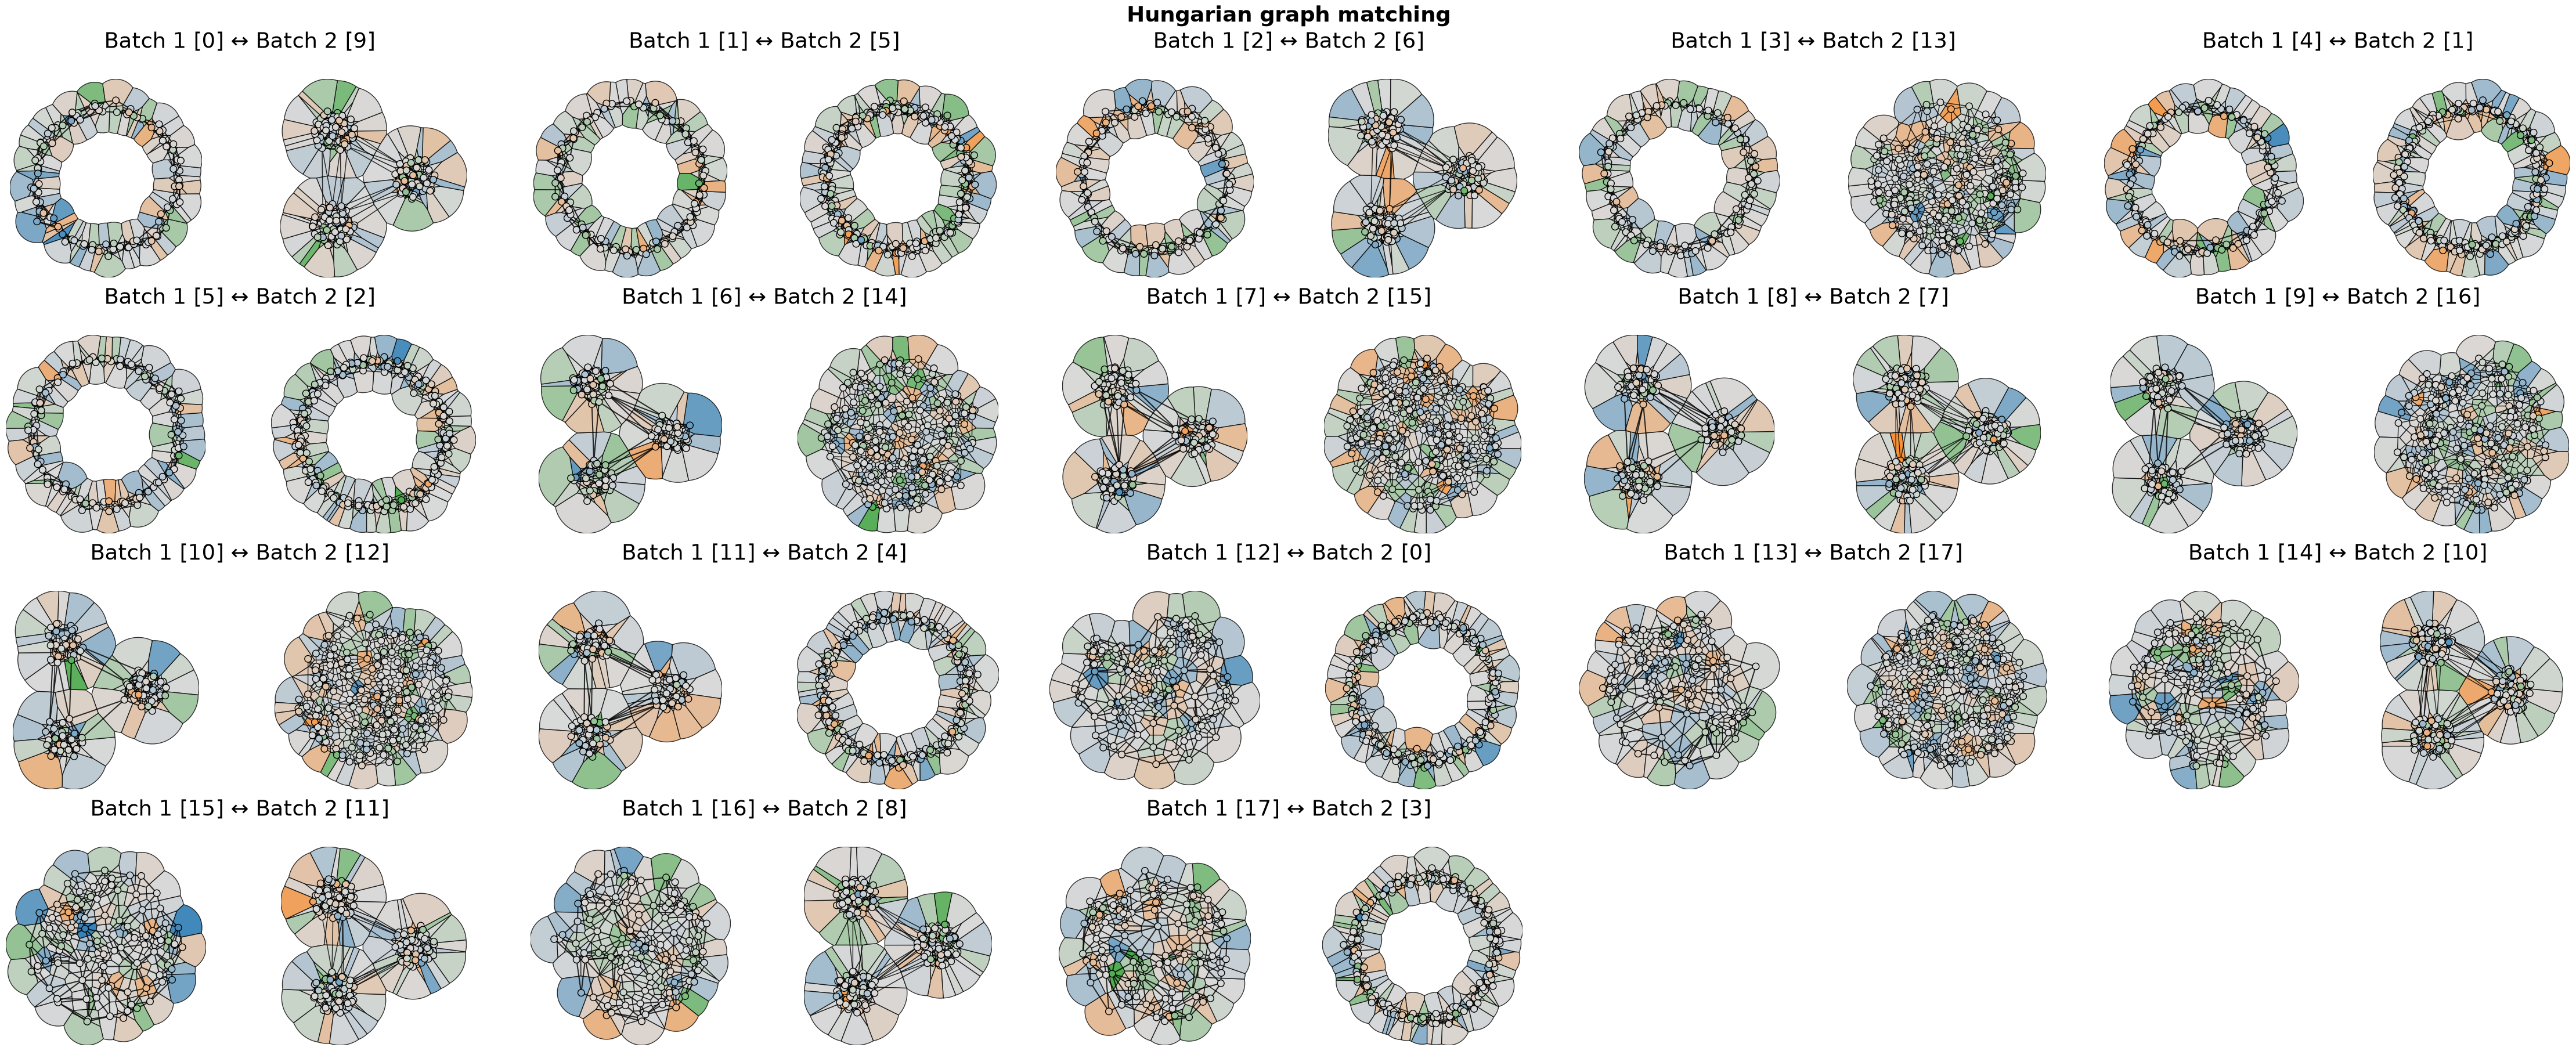

In [19]:
# Plot the graph-level coupling
opt.plot_coupling_hungarian(batches["0"], batches["1"], coupling_info["assignment"], voronoi = True, show_legend = False)